# Notebook 05 — Model Diagnostics

This notebook evaluates the two candidate regression models retained from Notebook 04 using the model-building sample.

The analysis focuses on residual behaviour, regression assumptions, outlying observations, leverage, and influence. The full eight-block model and the seven-block model excluding `Coupons` are examined in parallel.

The validation sample remains untouched and is reserved for final model validation.

## 1. Reconstruct Model-Building Sample

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [2]:
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = (
    PROCESSED_DATA_DIR
    / "db1c_ticket_prepared_202606.parquet"
)

df = pd.read_parquet(DATA_FILE)

print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows:    90,086
Columns: 16


### 1.1 Reproduce the 50/50 Split

In [3]:
SPLIT_SEED = 42
TRAIN_SHARE = 0.50

rng = np.random.default_rng(SPLIT_SEED)

random_order = rng.permutation(len(df))
split_point = int(TRAIN_SHARE * len(df))

train_idx = random_order[:split_point]
validation_idx = random_order[split_point:]

model_df = (
    df.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

validation_df = (
    df.iloc[validation_idx]
    .copy()
    .reset_index(drop=True)
)

print(f"Model-building sample: {len(model_df):,}")
print(f"Validation sample:     {len(validation_df):,}")

Model-building sample: 45,043
Validation sample:     45,043


### 1.2 Reproduce Categorical Grouping

In [4]:
MIN_CATEGORY_COUNT = 100

# Carrier grouping based only on model-building data
carrier_counts = model_df["RpCarrier"].value_counts()

major_carriers = carrier_counts[
    carrier_counts >= MIN_CATEGORY_COUNT
].index

model_df["RpCarrier_Model"] = model_df["RpCarrier"].where(
    model_df["RpCarrier"].isin(major_carriers),
    "Other"
)

validation_df["RpCarrier_Model"] = validation_df["RpCarrier"].where(
    validation_df["RpCarrier"].isin(major_carriers),
    "Other"
)

# Origin-state grouping based only on model-building data
state_counts = model_df["OriginState"].value_counts()

major_states = state_counts[
    state_counts >= MIN_CATEGORY_COUNT
].index

model_df["OriginState_Model"] = model_df["OriginState"].where(
    model_df["OriginState"].isin(major_states),
    "Other"
)

validation_df["OriginState_Model"] = validation_df["OriginState"].where(
    validation_df["OriginState"].isin(major_states),
    "Other"
)

print(
    f"Carrier model categories: "
    f"{model_df['RpCarrier_Model'].nunique()}"
)

print(
    f"Origin-state model categories: "
    f"{model_df['OriginState_Model'].nunique()}"
)

Carrier model categories: 12
Origin-state model categories: 43


#### Interpretation

Notebook 05 reproduces the same model-building sample and categorical grouping rules used in Notebooks 03 and 04.

The validation sample remains reserved and is not used for diagnostic or model-refinement decisions.

## 2. Refit Candidate Models

Notebook 04 retained two candidate specifications for further examination:

1. the full eight-block model;
2. the seven-block model excluding `Coupons`.

Both models are refitted on the same model-building sample so that their diagnostic behaviour can be compared directly.

In [5]:
full_formula = """
TotalAmount ~
    TotalDistance
    + Coupons
    + C(RoundTrip, Treatment(reference=0))
    + C(OnLine, Treatment(reference=1))
    + C(PurchaseWindowGroup, Treatment(reference='21AP'))
    + C(RpCarrier_Model, Treatment(reference='AA'))
    + C(ItinGeoType, Treatment(reference=2))
    + C(OriginState_Model, Treatment(reference='CA'))
"""

reduced_formula = """
TotalAmount ~
    TotalDistance
    + C(RoundTrip, Treatment(reference=0))
    + C(OnLine, Treatment(reference=1))
    + C(PurchaseWindowGroup, Treatment(reference='21AP'))
    + C(RpCarrier_Model, Treatment(reference='AA'))
    + C(ItinGeoType, Treatment(reference=2))
    + C(OriginState_Model, Treatment(reference='CA'))
"""

full_model = smf.ols(
    formula=full_formula,
    data=model_df
).fit()

reduced_model = smf.ols(
    formula=reduced_formula,
    data=model_df
).fit()

print("Full 8-block model")
print(f"Observations:        {int(full_model.nobs):,}")
print(f"Parameters:          {int(full_model.df_model + 1)}")
print(f"R-squared:           {full_model.rsquared:.4f}")
print(f"Adjusted R-squared:  {full_model.rsquared_adj:.4f}")

print("\n7-block model without Coupons")
print(f"Observations:        {int(reduced_model.nobs):,}")
print(f"Parameters:          {int(reduced_model.df_model + 1)}")
print(f"R-squared:           {reduced_model.rsquared:.4f}")
print(f"Adjusted R-squared:  {reduced_model.rsquared_adj:.4f}")

Full 8-block model
Observations:        45,043
Parameters:          61
R-squared:           0.3854
Adjusted R-squared:  0.3846

7-block model without Coupons
Observations:        45,043
Parameters:          60
R-squared:           0.3854
Adjusted R-squared:  0.3846


#### Interpretation

The two candidate models have virtually identical in-sample fit, with adjusted $R^2$ of approximately 0.385.

The remaining analysis examines whether excluding `Coupons` provides any meaningful improvement in model diagnostics.

## 3. Residual Analysis

Residual analysis is used to assess functional-form adequacy, error variance, residual distribution, and unusual observations.

The same diagnostics are applied to both candidate models.

### 3.1 Residuals Versus Fitted Values

If the linear specification and constant-variance assumptions are reasonable, residuals should be distributed around zero without a systematic pattern.

Curvature may indicate functional-form misspecification, while changing residual spread may indicate heteroskedasticity.

In [6]:
diagnostic_data = pd.DataFrame({
    "Full_Fitted": full_model.fittedvalues,
    "Full_Residual": full_model.resid,
    "Reduced_Fitted": reduced_model.fittedvalues,
    "Reduced_Residual": reduced_model.resid
})

display(
    diagnostic_data.describe()
)

,Full_Fitted,Full_Residual,Reduced_Fitted,Reduced_Residual
count,45043.000000,4.504300e+04,45043.000000,4.504300e+04
mean,459.573963,8.795912e-11,459.573963,1.176457e-10
std,218.691228,2.761442e+02,218.680316,2.761528e+02
min,-183.010287,-9.900176e+02,-184.779189,-9.904209e+02
25%,311.952803,-1.328375e+02,312.154273,-1.328447e+02
50%,445.192617,-3.291469e+01,445.525079,-3.294064e+01
75%,597.570246,7.542790e+01,597.512293,7.549507e+01
max,2549.311064,6.159757e+03,2541.435586,6.159911e+03


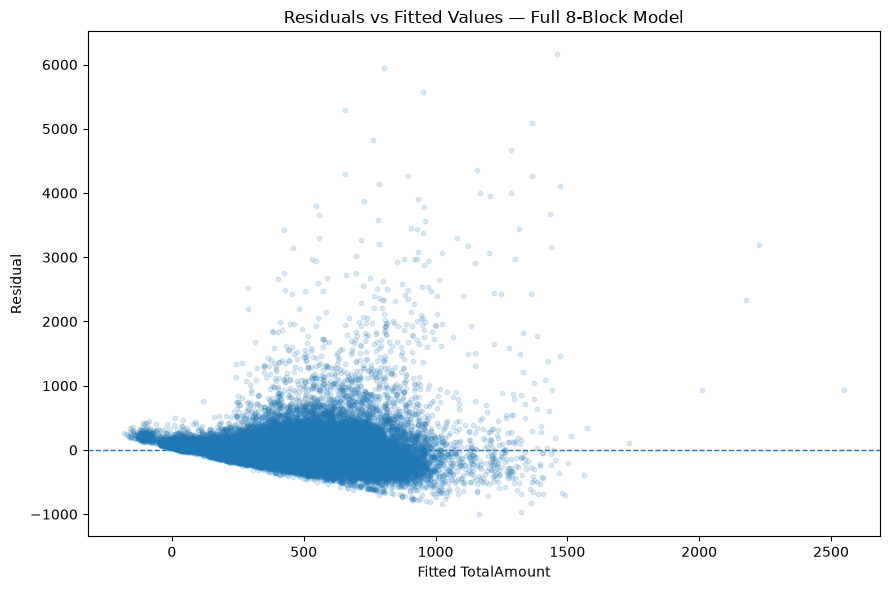

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    full_model.fittedvalues,
    full_model.resid,
    alpha=0.15,
    s=10
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Fitted TotalAmount")
ax.set_ylabel("Residual")
ax.set_title(
    "Residuals vs Fitted Values — Full 8-Block Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_full_model_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

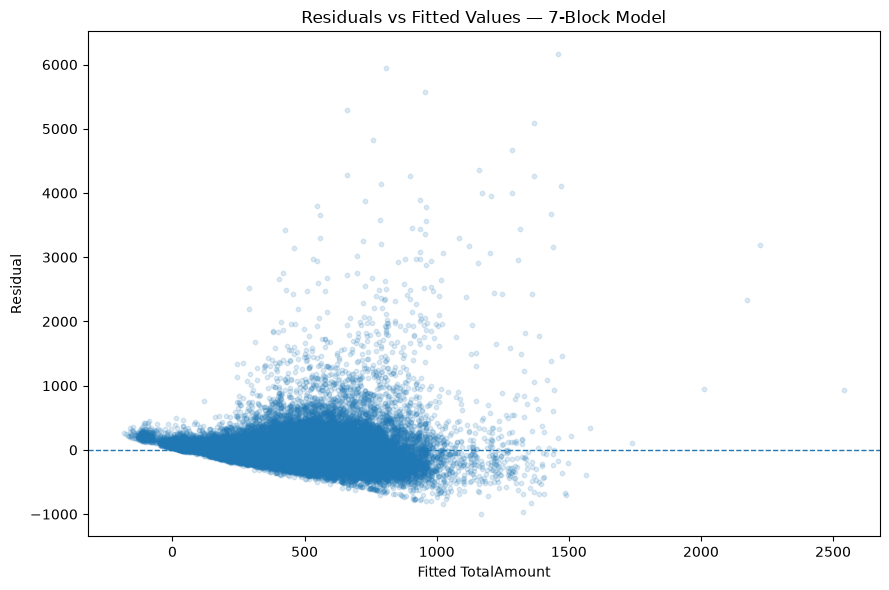

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    reduced_model.fittedvalues,
    reduced_model.resid,
    alpha=0.15,
    s=10
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Fitted TotalAmount")
ax.set_ylabel("Residual")
ax.set_title(
    "Residuals vs Fitted Values — 7-Block Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_reduced_model_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Both models show a pronounced fan-shaped residual pattern, with residual dispersion increasing as fitted fare rises. This provides visual evidence of heteroskedasticity.

The residuals are also asymmetric, with several large positive errors. A small number of fitted fares are negative despite `TotalAmount` being strictly positive, suggesting that the level-linear specification should be examined further.

The two models exhibit almost identical residual behaviour, so removing `Coupons` does not materially improve the residual pattern.

### 3.2 Partial Regression Plots

Partial regression plots examine the marginal relationship between a predictor and `TotalAmount` after controlling for the remaining predictors.

The analysis focuses on `TotalDistance`, the main continuous predictor, and `Coupons`, the variable distinguishing the two candidate models.

In [9]:
def partial_regression_data(
    data,
    response,
    target,
    control_terms
):
    # Residualize Y against all other predictors
    y_formula = (
        f"{response} ~ "
        + " + ".join(control_terms)
    )

    y_model = smf.ols(
        formula=y_formula,
        data=data
    ).fit()

    # Residualize target X against the same predictors
    x_formula = (
        f"{target} ~ "
        + " + ".join(control_terms)
    )

    x_model = smf.ols(
        formula=x_formula,
        data=data
    ).fit()

    return pd.DataFrame({
        "X_residual": x_model.resid,
        "Y_residual": y_model.resid
    })

In [10]:
full_controls_for_distance = [
    "Coupons",
    "C(RoundTrip, Treatment(reference=0))",
    "C(OnLine, Treatment(reference=1))",
    "C(PurchaseWindowGroup, Treatment(reference='21AP'))",
    "C(RpCarrier_Model, Treatment(reference='AA'))",
    "C(ItinGeoType, Treatment(reference=2))",
    "C(OriginState_Model, Treatment(reference='CA'))"
]

distance_partial = partial_regression_data(
    data=model_df,
    response="TotalAmount",
    target="TotalDistance",
    control_terms=full_controls_for_distance
)

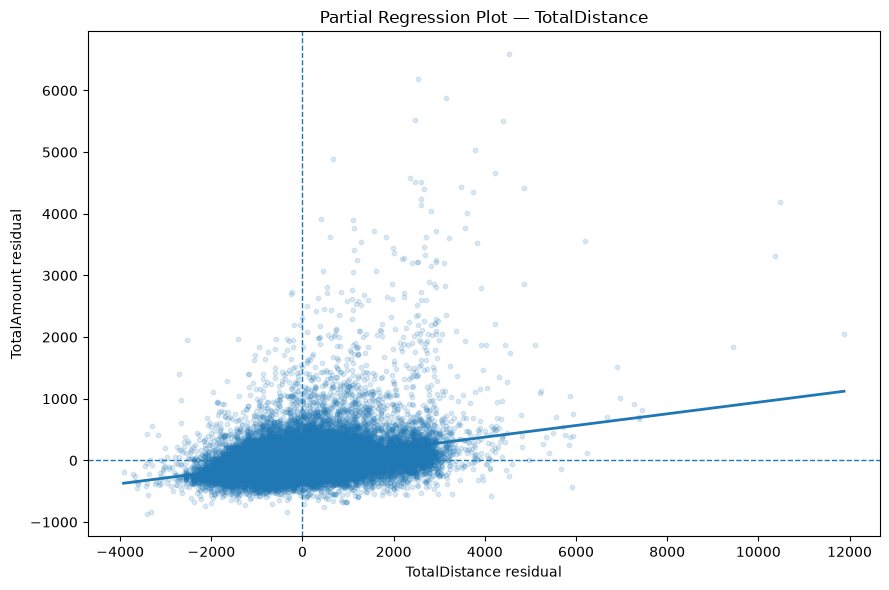

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    distance_partial["X_residual"],
    distance_partial["Y_residual"],
    alpha=0.15,
    s=10
)

# Linear fitted relationship
coef = np.polyfit(
    distance_partial["X_residual"],
    distance_partial["Y_residual"],
    1
)

x_line = np.linspace(
    distance_partial["X_residual"].min(),
    distance_partial["X_residual"].max(),
    200
)

ax.plot(
    x_line,
    coef[0] * x_line + coef[1],
    linewidth=2
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("TotalDistance residual")
ax.set_ylabel("TotalAmount residual")
ax.set_title(
    "Partial Regression Plot — TotalDistance"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_partial_regression_total_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
full_controls_for_coupons = [
    "TotalDistance",
    "C(RoundTrip, Treatment(reference=0))",
    "C(OnLine, Treatment(reference=1))",
    "C(PurchaseWindowGroup, Treatment(reference='21AP'))",
    "C(RpCarrier_Model, Treatment(reference='AA'))",
    "C(ItinGeoType, Treatment(reference=2))",
    "C(OriginState_Model, Treatment(reference='CA'))"
]

coupons_partial = partial_regression_data(
    data=model_df,
    response="TotalAmount",
    target="Coupons",
    control_terms=full_controls_for_coupons
)

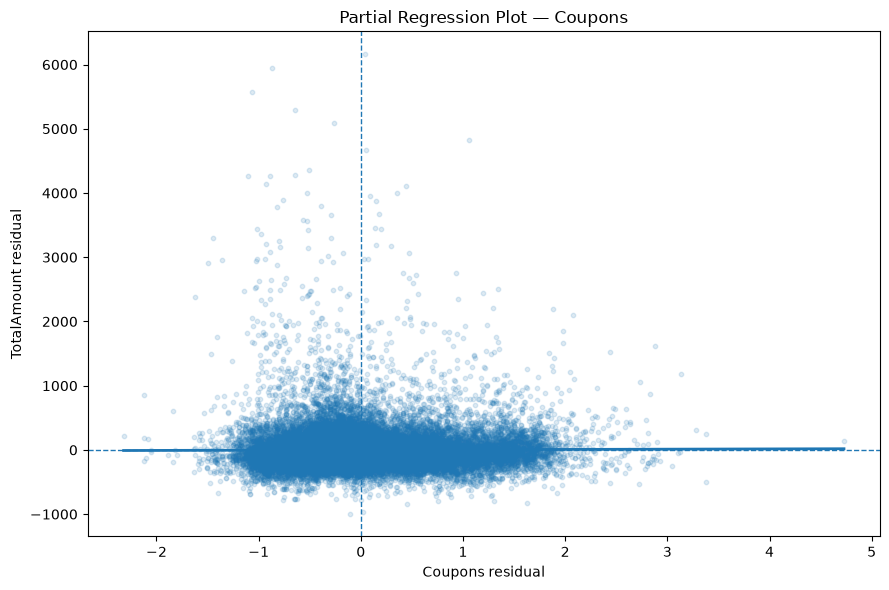

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    coupons_partial["X_residual"],
    coupons_partial["Y_residual"],
    alpha=0.15,
    s=10
)

coef = np.polyfit(
    coupons_partial["X_residual"],
    coupons_partial["Y_residual"],
    1
)

x_line = np.linspace(
    coupons_partial["X_residual"].min(),
    coupons_partial["X_residual"].max(),
    200
)

ax.plot(
    x_line,
    coef[0] * x_line + coef[1],
    linewidth=2
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Coupons residual")
ax.set_ylabel("TotalAmount residual")
ax.set_title(
    "Partial Regression Plot — Coupons"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_partial_regression_coupons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

`TotalDistance` retains a clear positive conditional relationship with `TotalAmount`, with no pronounced curvature suggesting that a first-order effect is clearly inadequate.

The partial relationship for `Coupons` is nearly flat, consistent with its weak incremental contribution identified in Notebook 04.

The increasing dispersion remains visible, suggesting that unequal error variance is a more prominent issue than nonlinearity in these numerical predictors.

### 3.3 Residual Distribution and Normality

Residual histograms and normal P–P plots are used to assess the normal-error assumption.

With the large model-building sample, moderate non-normality is less critical for coefficient inference than in a small sample. The emphasis is therefore on the severity and pattern of departure from normality.

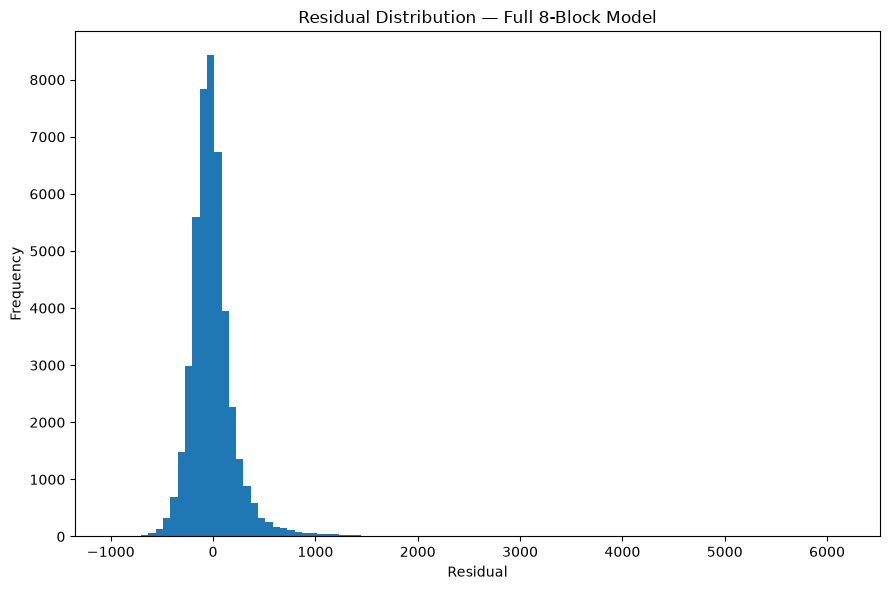

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    full_model.resid,
    bins=100
)

ax.set_xlabel("Residual")
ax.set_ylabel("Frequency")
ax.set_title(
    "Residual Distribution — Full 8-Block Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_full_model_residual_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

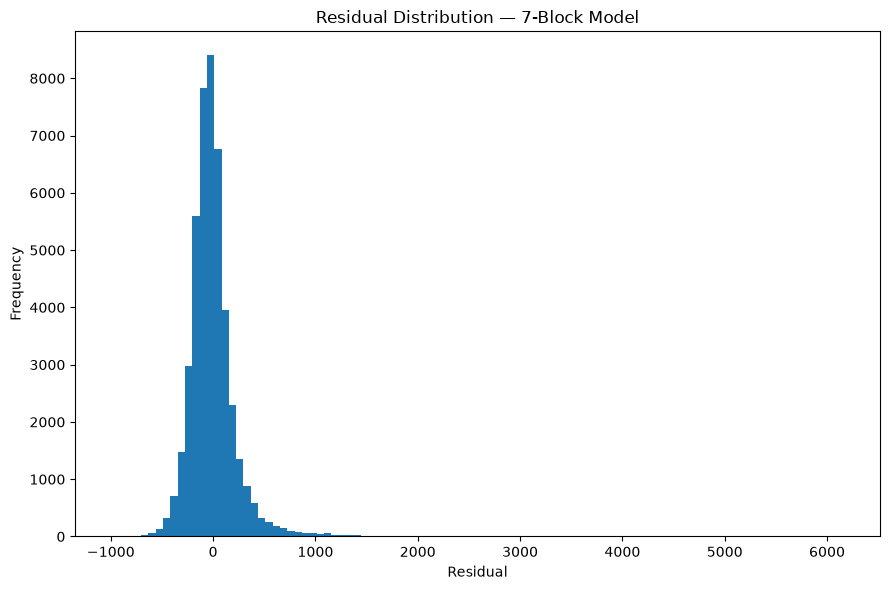

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    reduced_model.resid,
    bins=100
)

ax.set_xlabel("Residual")
ax.set_ylabel("Frequency")
ax.set_title(
    "Residual Distribution — 7-Block Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_reduced_model_residual_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
from scipy.stats import norm

def pp_plot(residuals, title, output_file):

    residuals = np.asarray(residuals)

    standardized = (
        residuals - residuals.mean()
    ) / residuals.std(ddof=1)

    standardized = np.sort(standardized)

    n = len(standardized)

    empirical_prob = (
        np.arange(1, n + 1) - 0.5
    ) / n

    theoretical_prob = norm.cdf(
        standardized
    )

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.scatter(
        theoretical_prob,
        empirical_prob,
        alpha=0.4,
        s=10
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        "Theoretical Normal Cumulative Probability"
    )

    ax.set_ylabel(
        "Observed Cumulative Probability"
    )

    ax.set_title(title)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

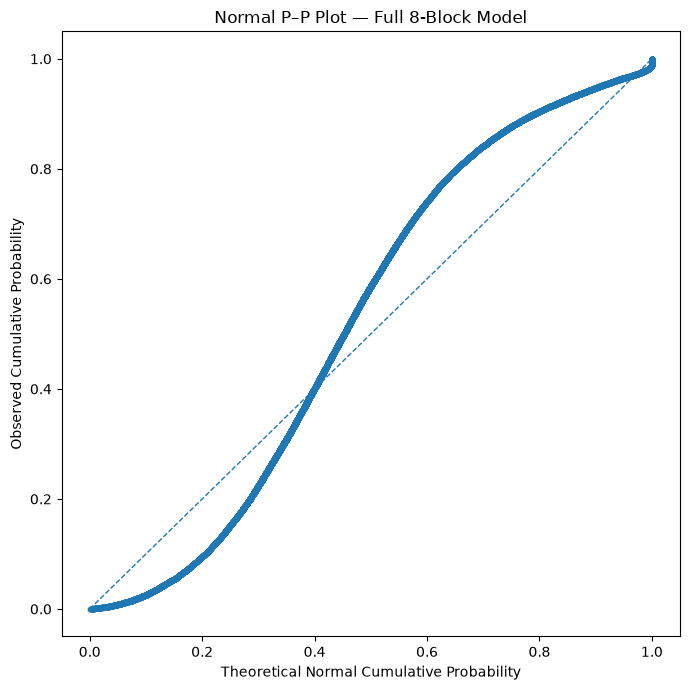

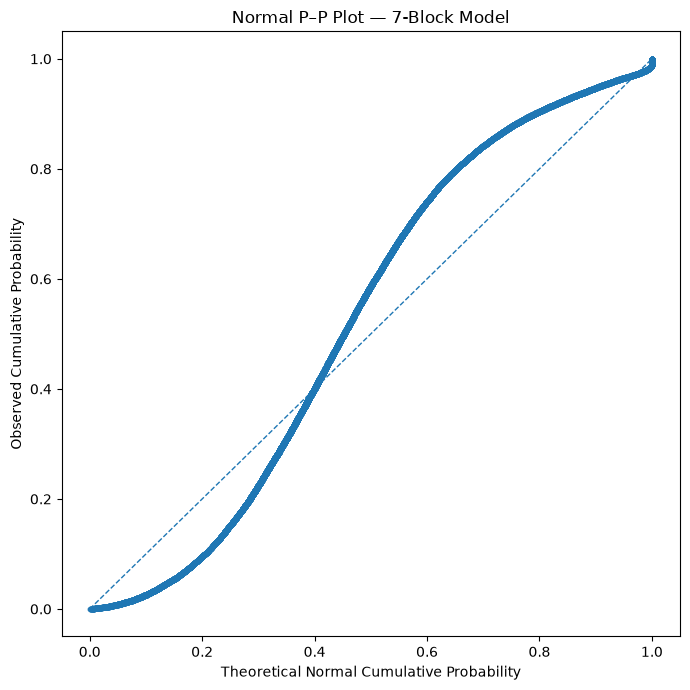

In [17]:
pp_plot(
    full_model.resid,
    "Normal P–P Plot — Full 8-Block Model",
    "05_full_model_pp_plot.png"
)

pp_plot(
    reduced_model.resid,
    "Normal P–P Plot — 7-Block Model",
    "05_reduced_model_pp_plot.png"
)

#### Interpretation

Both models have strongly right-skewed residual distributions with long positive tails. The P–P plots also show clear systematic departures from the normal reference line.

Removing `Coupons` produces virtually no improvement in residual normality.

Although normality is not required for OLS to be BLUE and large-sample inference is less sensitive to non-normal errors, the pronounced skewness remains relevant for model refinement and may be related to the unequal variance observed earlier.

## 4. Constant Variance and BLUE Assessment

The residual-versus-fitted plots suggest that residual variance increases with fitted fare.

The Breusch–Pagan test is used to formally assess the constant-error-variance assumption.

### 4.1 Breusch–Pagan Test

In [18]:
from statsmodels.stats.diagnostic import het_breuschpagan

def breusch_pagan_results(model, model_name):

    lm_stat, lm_pvalue, f_stat, f_pvalue = (
        het_breuschpagan(
            model.resid,
            model.model.exog
        )
    )

    return {
        "Model": model_name,
        "LM_Statistic": lm_stat,
        "LM_p_value": lm_pvalue,
        "F_Statistic": f_stat,
        "F_p_value": f_pvalue
    }


bp_results = pd.DataFrame([
    breusch_pagan_results(
        full_model,
        "Full 8-block model"
    ),
    breusch_pagan_results(
        reduced_model,
        "7-block model"
    )
])

display(bp_results)

,Model,LM_Statistic,LM_p_value,F_Statistic,F_p_value
0,Full 8-block model,1590.790017,5.633910e-293,27.446597,0.0
1,7-block model,1571.323725,1.282811e-289,27.558507,0.0


In [19]:
bp_results.to_csv(
    OUTPUT_DIR / "05_breusch_pagan_results.csv",
    index=False
)

#### Interpretation

The Breusch–Pagan test strongly rejects constant error variance for both models:

- Full model: $LM=1590.79$, $p<0.001$.
- Seven-block model: $LM=1571.32$, $p<0.001$.

This confirms the heteroskedasticity observed in the residual plots. Removing `Coupons` does not resolve the unequal-variance problem.

### 4.2 Implication for BLUE

With unequal error variances, OLS estimators may remain unbiased and consistent if the other assumptions hold, but they no longer have minimum variance.

Therefore, under the current specification:

$$
\boxed{\text{OLS is not BLUE}}
$$

because the constant-error-variance condition is violated.

Remedial measures will be examined after completing the remaining diagnostics.

## 5. Outlying Y Observations

Studentized deleted residuals are used to identify observations with unusually large response errors while accounting for differences in residual variance.

A Bonferroni procedure is used to formally identify the most extreme observations.

In [20]:
from scipy.stats import t

def studentized_deleted_residuals(model):

    residuals = np.asarray(model.resid)
    X = model.model.exog

    # Hat-matrix diagonal:
    # h_ii = x_i'(X'X)^(-1)x_i
    leverage = np.sum(
        X * model.model.pinv_wexog.T,
        axis=1
    )

    n = int(model.nobs)
    p = int(model.df_model + 1)
    sse = model.ssr

    denominator = (
        sse * (1 - leverage)
        - residuals**2
    )

    studentized_deleted = (
        residuals
        * np.sqrt(
            (n - p - 1)
            / denominator
        )
    )

    return studentized_deleted, leverage

In [21]:
full_studentized_deleted, full_leverage = (
    studentized_deleted_residuals(full_model)
)

reduced_studentized_deleted, reduced_leverage = (
    studentized_deleted_residuals(reduced_model)
)

In [22]:
outlier_data = model_df[
    [
        "ItinID",
        "TotalAmount",
        "TotalDistance",
        "Coupons"
    ]
].copy()

outlier_data["Full_Fitted"] = (
    full_model.fittedvalues
)

outlier_data["Full_Residual"] = (
    full_model.resid
)

outlier_data["Full_Studentized_Deleted"] = (
    full_studentized_deleted
)

outlier_data["Reduced_Fitted"] = (
    reduced_model.fittedvalues
)

outlier_data["Reduced_Residual"] = (
    reduced_model.resid
)

outlier_data["Reduced_Studentized_Deleted"] = (
    reduced_studentized_deleted
)

In [23]:
ALPHA = 0.05

n_full = int(full_model.nobs)
p_full = int(full_model.df_model + 1)

n_reduced = int(reduced_model.nobs)
p_reduced = int(reduced_model.df_model + 1)

full_bonferroni_critical = t.ppf(
    1 - ALPHA / (2 * n_full),
    df=n_full - p_full - 1
)

reduced_bonferroni_critical = t.ppf(
    1 - ALPHA / (2 * n_reduced),
    df=n_reduced - p_reduced - 1
)

print(
    f"Full model Bonferroni critical value: "
    f"{full_bonferroni_critical:.4f}"
)

print(
    f"7-block model Bonferroni critical value: "
    f"{reduced_bonferroni_critical:.4f}"
)

Full model Bonferroni critical value: 4.8717
7-block model Bonferroni critical value: 4.8717


In [24]:
outlier_data["Full_Bonferroni_Outlier"] = (
    outlier_data[
        "Full_Studentized_Deleted"
    ].abs()
    > full_bonferroni_critical
)

outlier_data["Reduced_Bonferroni_Outlier"] = (
    outlier_data[
        "Reduced_Studentized_Deleted"
    ].abs()
    > reduced_bonferroni_critical
)

print(
    "Full-model Bonferroni outliers:",
    outlier_data[
        "Full_Bonferroni_Outlier"
    ].sum()
)

print(
    "7-block-model Bonferroni outliers:",
    outlier_data[
        "Reduced_Bonferroni_Outlier"
    ].sum()
)

Full-model Bonferroni outliers: 254
7-block-model Bonferroni outliers: 254


In [25]:
top_full_outliers = (
    outlier_data
    .assign(
        Abs_Studentized_Deleted=lambda x:
        x["Full_Studentized_Deleted"].abs()
    )
    .sort_values(
        "Abs_Studentized_Deleted",
        ascending=False
    )
    .head(20)
)

display(
    top_full_outliers[
        [
            "ItinID",
            "TotalAmount",
            "TotalDistance",
            "Coupons",
            "Full_Fitted",
            "Full_Residual",
            "Full_Studentized_Deleted",
            "Full_Bonferroni_Outlier"
        ]
    ]
)

,ItinID,TotalAmount,TotalDistance,Coupons,Full_Fitted,Full_Residual,Full_Studentized_Deleted,Full_Bonferroni_Outlier
10481,20260616048354,7620.50,10314.0,5,1460.742959,6159.757041,22.438052,True
13571,20260623053732,6752.50,5130.0,2,804.683330,5947.816670,21.641482,True
23926,20260619206562,6530.31,5172.0,2,952.057512,5578.252488,20.286913,True
13325,2026066534112,5947.62,4950.0,2,657.040288,5290.579712,19.233466,True
33146,20260616477402,6451.98,10192.0,4,1365.537509,5086.442491,18.490482,True
42787,20260616900626,5584.39,4235.0,4,764.644254,4819.745746,17.506077,True
34820,20260622871734,5960.38,9572.0,4,1286.072895,4674.307105,16.983834,True
22195,20260611709618,5522.89,7644.0,4,1159.014411,4363.875589,15.845837,True
23801,2026066415049,4946.80,4950.0,2,657.040288,4289.759712,15.573146,True
32100,20260616641893,5629.80,9216.0,4,1364.503267,4265.296733,15.494547,True


In [26]:
top_reduced_outliers = (
    outlier_data
    .assign(
        Abs_Studentized_Deleted=lambda x:
        x["Reduced_Studentized_Deleted"].abs()
    )
    .sort_values(
        "Abs_Studentized_Deleted",
        ascending=False
    )
    .head(20)
)

display(
    top_reduced_outliers[
        [
            "ItinID",
            "TotalAmount",
            "TotalDistance",
            "Coupons",
            "Reduced_Fitted",
            "Reduced_Residual",
            "Reduced_Studentized_Deleted",
            "Reduced_Bonferroni_Outlier"
        ]
    ]
)

,ItinID,TotalAmount,TotalDistance,Coupons,Reduced_Fitted,Reduced_Residual,Reduced_Studentized_Deleted,Reduced_Bonferroni_Outlier
10481,20260616048354,7620.50,10314.0,5,1460.589369,6159.910631,22.438156,True
13571,20260623053732,6752.50,5130.0,2,808.047756,5944.452244,21.628094,True
23926,20260619206562,6530.31,5172.0,2,956.194298,5574.115702,20.270501,True
13325,2026066534112,5947.62,4950.0,2,659.541518,5288.078482,19.223623,True
33146,20260616477402,6451.98,10192.0,4,1366.544821,5085.435179,18.486371,True
42787,20260616900626,5584.39,4235.0,4,760.530935,4823.859065,17.520067,True
34820,20260622871734,5960.38,9572.0,4,1285.875742,4674.504258,16.984207,True
22195,20260611709618,5522.89,7644.0,4,1160.964269,4361.925731,15.838254,True
23801,2026066415049,4946.80,4950.0,2,659.541518,4287.258482,15.563473,True
32100,20260616641893,5629.80,9216.0,4,1368.778008,4261.021992,15.477958,True


In [27]:
bonferroni_outliers = outlier_data[
    outlier_data["Full_Bonferroni_Outlier"]
    | outlier_data["Reduced_Bonferroni_Outlier"]
].copy()

bonferroni_outliers.to_csv(
    OUTPUT_DIR / "05_bonferroni_outliers.csv",
    index=False
)

print(
    f"Unique observations flagged by either model: "
    f"{len(bonferroni_outliers):,}"
)

Unique observations flagged by either model: 254


#### Interpretation

Both models identify 254 Bonferroni response outliers, representing approximately 0.56% of the model-building sample.

The critical value is approximately $|t_i|>4.872$, while the largest studentized deleted residual is about 22.44. The most extreme cases are associated with large positive residuals.

Exactly the same 254 observations are flagged by both models. These observations are retained because an outlier is not necessarily influential; leverage and influence are examined next.

## 6. Leverage and Outlying X Observations

Leverage measures how unusual an observation's predictor values are relative to the rest of the sample.

Following the lecture guideline, relatively high leverage is identified using:

$$
h_{ii}>\frac{2p}{n}.
$$

High leverage alone does not imply that an observation is influential.

In [28]:
full_leverage_threshold = (
    2 * p_full / n_full
)

reduced_leverage_threshold = (
    2 * p_reduced / n_reduced
)

print(
    f"Full-model leverage threshold: "
    f"{full_leverage_threshold:.6f}"
)

print(
    f"7-block leverage threshold: "
    f"{reduced_leverage_threshold:.6f}"
)

print(
    f"\nFull-model maximum leverage: "
    f"{full_leverage.max():.6f}"
)

print(
    f"7-block maximum leverage: "
    f"{reduced_leverage.max():.6f}"
)

Full-model leverage threshold: 0.002709
7-block leverage threshold: 0.002664

Full-model maximum leverage: 0.014086
7-block maximum leverage: 0.014084


In [29]:
outlier_data["Full_Leverage"] = (
    full_leverage
)

outlier_data["Reduced_Leverage"] = (
    reduced_leverage
)

outlier_data["Full_High_Leverage"] = (
    outlier_data["Full_Leverage"]
    > full_leverage_threshold
)

outlier_data["Reduced_High_Leverage"] = (
    outlier_data["Reduced_Leverage"]
    > reduced_leverage_threshold
)

print(
    "Full-model high-leverage observations:",
    outlier_data[
        "Full_High_Leverage"
    ].sum()
)

print(
    "7-block high-leverage observations:",
    outlier_data[
        "Reduced_High_Leverage"
    ].sum()
)

Full-model high-leverage observations: 4602
7-block high-leverage observations: 4676


In [30]:
top_full_leverage = (
    outlier_data
    .sort_values(
        "Full_Leverage",
        ascending=False
    )
    .head(20)
)

display(
    top_full_leverage[
        [
            "ItinID",
            "TotalAmount",
            "TotalDistance",
            "Coupons",
            "Full_Fitted",
            "Full_Residual",
            "Full_Studentized_Deleted",
            "Full_Leverage",
            "Full_High_Leverage"
        ]
    ]
)

,ItinID,TotalAmount,TotalDistance,Coupons,Full_Fitted,Full_Residual,Full_Studentized_Deleted,Full_Leverage,Full_High_Leverage
17882,2026065944292,134.50,152.0,1,259.238280,-124.738280,-0.454623,0.014086,True
27639,20260619818068,133.20,34.0,2,445.308238,-312.108238,-1.136968,0.013116,True
35313,20260619817898,113.77,34.0,2,445.308238,-331.538238,-1.207751,0.013116,True
10687,20260619818089,66.36,17.0,1,298.832686,-232.472686,-0.846843,0.013075,True
44584,20260619817953,71.22,17.0,1,298.832686,-227.612686,-0.829139,0.013075,True
34424,20260611240531,206.58,2272.0,2,275.007778,-68.427778,-0.249127,0.011985,True
2070,20260611243505,92.59,1117.0,1,73.442068,19.147932,0.069684,0.011184,True
14563,202606332047,278.00,448.0,2,475.625526,-197.625526,-0.719085,0.010832,True
30407,20260623828439,10.14,186.0,1,265.898730,-255.758730,-0.930484,0.010557,True
2078,202606325634,236.00,728.0,2,339.046957,-103.046957,-0.374841,0.010268,True


In [31]:
high_leverage_cases = outlier_data[
    outlier_data["Full_High_Leverage"]
    | outlier_data["Reduced_High_Leverage"]
].copy()

high_leverage_cases.to_csv(
    OUTPUT_DIR / "05_high_leverage_cases.csv",
    index=False
)

print(
    f"Unique high-leverage observations "
    f"flagged by either model: "
    f"{len(high_leverage_cases):,}"
)

Unique high-leverage observations flagged by either model: 4,695


#### Interpretation

The leverage thresholds are approximately 0.00271 for the full model and 0.00266 for the seven-block model, flagging 4,602 and 4,676 observations respectively.

However, the maximum leverage is only about 0.014 for both models, far below the lecture guidelines of 0.2 for moderate and 0.5 for very high leverage.

Thus, many observations are relatively unusual compared with the mean leverage, but none has extreme leverage in absolute terms. The two candidate models again show very similar behaviour.

## 7. Influence Diagnostics

Influence diagnostics assess whether individual observations materially affect fitted values or regression coefficients.

DFFITS, Cook's distance and DFBETAS are examined.

### 7.1 DFFITS

DFFITS measures the effect of deleting observation $i$ on its own fitted value:

$$
\mathrm{DFFITS}_i
=
t_i
\sqrt{\frac{h_{ii}}{1-h_{ii}}}.
$$

For a large dataset, the lecture guideline is:

$$
|\mathrm{DFFITS}_i|
>
2\sqrt{\frac{p}{n}}.
$$

In [32]:
full_dffits = (
    full_studentized_deleted
    * np.sqrt(
        full_leverage
        / (1 - full_leverage)
    )
)

reduced_dffits = (
    reduced_studentized_deleted
    * np.sqrt(
        reduced_leverage
        / (1 - reduced_leverage)
    )
)

full_dffits_threshold = (
    2 * np.sqrt(p_full / n_full)
)

reduced_dffits_threshold = (
    2 * np.sqrt(p_reduced / n_reduced)
)

print(
    f"Full-model DFFITS threshold: "
    f"{full_dffits_threshold:.6f}"
)

print(
    f"7-block DFFITS threshold: "
    f"{reduced_dffits_threshold:.6f}"
)

Full-model DFFITS threshold: 0.073601
7-block DFFITS threshold: 0.072995


In [33]:
outlier_data["Full_DFFITS"] = full_dffits
outlier_data["Reduced_DFFITS"] = reduced_dffits

outlier_data["Full_DFFITS_Flag"] = (
    np.abs(full_dffits)
    > full_dffits_threshold
)

outlier_data["Reduced_DFFITS_Flag"] = (
    np.abs(reduced_dffits)
    > reduced_dffits_threshold
)

print(
    "Full-model DFFITS flags:",
    outlier_data[
        "Full_DFFITS_Flag"
    ].sum()
)

print(
    "7-block DFFITS flags:",
    outlier_data[
        "Reduced_DFFITS_Flag"
    ].sum()
)

print(
    f"\nMaximum absolute full-model DFFITS: "
    f"{np.abs(full_dffits).max():.6f}"
)

print(
    f"Maximum absolute 7-block DFFITS: "
    f"{np.abs(reduced_dffits).max():.6f}"
)

Full-model DFFITS flags: 1384
7-block DFFITS flags: 1371

Maximum absolute full-model DFFITS: 1.115911
Maximum absolute 7-block DFFITS: 1.114942


### 7.2 Cook's Distance

Cook's distance measures the influence of observation $i$ on all fitted values:

$$
D_i
=
\frac{e_i^2}{p\,MSE}
\frac{h_{ii}}{(1-h_{ii})^2}.
$$

It reflects both residual magnitude and leverage.

In [34]:
def cooks_distance(model, leverage):

    residuals = np.asarray(model.resid)

    p = int(model.df_model + 1)

    mse = model.mse_resid

    cooks_d = (
        (residuals**2 / (p * mse))
        * (
            leverage
            / (1 - leverage)**2
        )
    )

    return cooks_d

In [35]:
full_cooks_d = cooks_distance(
    full_model,
    full_leverage
)

reduced_cooks_d = cooks_distance(
    reduced_model,
    reduced_leverage
)

outlier_data["Full_Cooks_D"] = (
    full_cooks_d
)

outlier_data["Reduced_Cooks_D"] = (
    reduced_cooks_d
)

print(
    f"Maximum full-model Cook's distance: "
    f"{full_cooks_d.max():.6f}"
)

print(
    f"Maximum 7-block Cook's distance: "
    f"{reduced_cooks_d.max():.6f}"
)

Maximum full-model Cook's distance: 0.020314
Maximum 7-block Cook's distance: 0.020616


In [36]:
top_influential = (
    outlier_data
    .sort_values(
        "Full_Cooks_D",
        ascending=False
    )
    .head(20)
)

display(
    top_influential[
        [
            "ItinID",
            "TotalAmount",
            "TotalDistance",
            "Coupons",
            "Full_Studentized_Deleted",
            "Full_Leverage",
            "Full_DFFITS",
            "Full_Cooks_D"
        ]
    ]
)

,ItinID,TotalAmount,TotalDistance,Coupons,Full_Studentized_Deleted,Full_Leverage,Full_DFFITS,Full_Cooks_D
27340,20260616962288,5579.80,9462.0,6,14.941890,0.005547,1.115911,0.020314
43512,20260610875096,5291.06,9269.0,5,14.573834,0.005580,1.091672,0.019445
10481,20260616048354,7620.50,10314.0,5,22.438052,0.002000,1.004493,0.016358
28080,20260622139504,5420.54,17916.0,6,11.604988,0.004643,0.792623,0.010269
2487,20260615409325,5160.49,10125.0,4,14.368231,0.002848,0.767896,0.009623
32100,20260616641893,5629.80,9216.0,4,15.494547,0.002318,0.746839,0.009095
41149,20260616724169,3773.80,4288.0,4,10.607459,0.004716,0.730168,0.008718
2865,20260619271927,4526.43,4862.0,3,12.955268,0.003020,0.713061,0.008305
33146,20260616477402,6451.98,10192.0,4,18.490482,0.001473,0.710063,0.008203
34820,20260622871734,5960.38,9572.0,4,16.983834,0.001659,0.692411,0.007810


In [37]:
print(
    "Bonferroni outlier + DFFITS flag:",
    (
        outlier_data[
            "Full_Bonferroni_Outlier"
        ]
        & outlier_data[
            "Full_DFFITS_Flag"
        ]
    ).sum()
)

print(
    "High leverage + DFFITS flag:",
    (
        outlier_data[
            "Full_High_Leverage"
        ]
        & outlier_data[
            "Full_DFFITS_Flag"
        ]
    ).sum()
)

Bonferroni outlier + DFFITS flag: 254
High leverage + DFFITS flag: 470


#### Interpretation

DFFITS flags 1,384 observations in the full model and 1,371 in the seven-block model. All 254 Bonferroni response outliers are also flagged, while only 470 of the 4,602 high-leverage observations in the full model are flagged.

Maximum Cook's distance is only about 0.02 for both models. Thus, some observations are locally influential, particularly those with extreme positive residuals, but no single observation appears to dominate the fitted regression as a whole.

The two candidate models again show very similar influence patterns.

### 7.3 DFBETAS

DFBETAS measures the influence of observation $i$ on each estimated coefficient.

For a large dataset, the lecture guideline is:

$$
|\mathrm{DFBETAS}|
>
\frac{2}{\sqrt{n}}.
$$

In [38]:
def calculate_dfbetas(
    model,
    leverage,
    studentized_deleted
):

    X = model.model.exog
    xtx_inv = model.normalized_cov_params

    # Diagonal elements of (X'X)^(-1)
    ckk = np.diag(xtx_inv)

    # DFBETAS analytical form
    scale = (
        studentized_deleted
        / np.sqrt(1 - leverage)
    )

    adjustment = (
        X @ xtx_inv
    )

    dfbetas = (
        adjustment
        * scale[:, None]
        / np.sqrt(ckk)[None, :]
    )

    return dfbetas

In [39]:
full_dfbetas = calculate_dfbetas(
    full_model,
    full_leverage,
    full_studentized_deleted
)

reduced_dfbetas = calculate_dfbetas(
    reduced_model,
    reduced_leverage,
    reduced_studentized_deleted
)

full_dfbetas_threshold = (
    2 / np.sqrt(n_full)
)

reduced_dfbetas_threshold = (
    2 / np.sqrt(n_reduced)
)

print(
    f"Full-model DFBETAS threshold: "
    f"{full_dfbetas_threshold:.6f}"
)

print(
    f"7-block DFBETAS threshold: "
    f"{reduced_dfbetas_threshold:.6f}"
)

Full-model DFBETAS threshold: 0.009424
7-block DFBETAS threshold: 0.009424


In [40]:
full_max_abs_dfbetas = (
    np.abs(full_dfbetas).max(axis=1)
)

reduced_max_abs_dfbetas = (
    np.abs(reduced_dfbetas).max(axis=1)
)

outlier_data["Full_Max_Abs_DFBETAS"] = (
    full_max_abs_dfbetas
)

outlier_data["Reduced_Max_Abs_DFBETAS"] = (
    reduced_max_abs_dfbetas
)

outlier_data["Full_DFBETAS_Flag"] = (
    full_max_abs_dfbetas
    > full_dfbetas_threshold
)

outlier_data["Reduced_DFBETAS_Flag"] = (
    reduced_max_abs_dfbetas
    > reduced_dfbetas_threshold
)

print(
    "Full-model observations with at least "
    "one DFBETAS flag:",
    outlier_data[
        "Full_DFBETAS_Flag"
    ].sum()
)

print(
    "7-block observations with at least "
    "one DFBETAS flag:",
    outlier_data[
        "Reduced_DFBETAS_Flag"
    ].sum()
)

print(
    f"\nMaximum absolute DFBETAS — full model: "
    f"{full_max_abs_dfbetas.max():.6f}"
)

print(
    f"Maximum absolute DFBETAS — 7-block model: "
    f"{reduced_max_abs_dfbetas.max():.6f}"
)

Full-model observations with at least one DFBETAS flag: 21012
7-block observations with at least one DFBETAS flag: 21042

Maximum absolute DFBETAS — full model: 0.969758
Maximum absolute DFBETAS — 7-block model: 0.976483


In [41]:
full_dfbetas_summary = pd.DataFrame({
    "Coefficient": full_model.model.exog_names,
    "Max_Abs_DFBETAS": np.abs(
        full_dfbetas
    ).max(axis=0),
    "Number_Flagged": (
        np.abs(full_dfbetas)
        > full_dfbetas_threshold
    ).sum(axis=0)
})

full_dfbetas_summary = (
    full_dfbetas_summary
    .sort_values(
        "Max_Abs_DFBETAS",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    full_dfbetas_summary.head(20)
)

,Coefficient,Max_Abs_DFBETAS,Number_Flagged
0,"C(OriginState_Model, Treatment(reference='CA')...",0.969758,314
1,"C(OriginState_Model, Treatment(reference='CA')...",0.687164,292
2,"C(OriginState_Model, Treatment(reference='CA')...",0.623143,175
3,"C(OriginState_Model, Treatment(reference='CA')...",0.578742,542
4,TotalDistance,0.573946,2054
5,"C(RpCarrier_Model, Treatment(reference='AA'))[...",0.520662,380
6,"C(OriginState_Model, Treatment(reference='CA')...",0.485936,1470
7,"C(OriginState_Model, Treatment(reference='CA')...",0.477107,853
8,"C(OriginState_Model, Treatment(reference='CA')...",0.476781,1030
9,"C(OriginState_Model, Treatment(reference='CA')...",0.436352,285


In [42]:
full_dfbetas_summary.to_csv(
    OUTPUT_DIR / "05_dfbetas_summary.csv",
    index=False
)

In [43]:
dfbetas_sensitivity = pd.DataFrame({
    "Threshold": [
        full_dfbetas_threshold,
        0.05,
        0.10,
        0.20,
        0.50,
        1.00
    ]
})

dfbetas_sensitivity[
    "Observations_Exceeding"
] = [
    (
        full_max_abs_dfbetas > threshold
    ).sum()
    for threshold in dfbetas_sensitivity[
        "Threshold"
    ]
]

dfbetas_sensitivity[
    "Percentage"
] = (
    dfbetas_sensitivity[
        "Observations_Exceeding"
    ]
    / n_full
    * 100
)

display(dfbetas_sensitivity)

,Threshold,Observations_Exceeding,Percentage
0,0.009424,21012,46.648758
1,0.050000,1973,4.380259
2,0.100000,474,1.052328
3,0.200000,98,0.217570
4,0.500000,7,0.015541
5,1.000000,0,0.000000


In [44]:
dfbetas_sensitivity.to_csv(
    OUTPUT_DIR / "05_dfbetas_sensitivity.csv",
    index=False
)

#### Interpretation

The large-sample DFBETAS threshold is 0.00942, causing 21,012 observations in the full model to exceed the guideline for at least one coefficient.

This high count reflects the very small threshold and the large number of coefficients being examined. Larger effects are much less common: only 1.05% of observations exceed 0.10, 0.22% exceed 0.20, and seven observations exceed 0.50.

The largest effects mainly involve origin-state and carrier indicators, with some sensitivity in `TotalDistance`. Overall, the evidence suggests localized coefficient influence rather than widespread model instability.

## 8. Independence of Errors

The dataset is cross-sectional and has no meaningful sequential time ordering. Therefore, time-series autocorrelation tests such as Durbin–Watson or Breusch–Godfrey are not appropriate.

Error independence cannot be directly verified from the available data and remains a modelling assumption.

## 9. Candidate-Model Diagnostic Comparison

The main diagnostic results for the two candidate models are summarized below to assess whether excluding `Coupons` materially improves model behaviour.

In [45]:
diagnostic_summary = pd.DataFrame({
    "Metric": [
        "R-squared",
        "Adjusted R-squared",
        "Breusch-Pagan LM",
        "Breusch-Pagan p-value",
        "Bonferroni outliers",
        "Maximum |studentized deleted residual|",
        "High-leverage observations",
        "Maximum leverage",
        "DFFITS flags",
        "Maximum |DFFITS|",
        "Maximum Cook's distance",
        "Observations with >=1 DFBETAS flag",
        "Maximum |DFBETAS|"
    ],

    "Full 8-block model": [
        full_model.rsquared,
        full_model.rsquared_adj,
        bp_results.loc[0, "LM_Statistic"],
        bp_results.loc[0, "LM_p_value"],
        int(outlier_data["Full_Bonferroni_Outlier"].sum()),
        np.abs(full_studentized_deleted).max(),
        int(outlier_data["Full_High_Leverage"].sum()),
        full_leverage.max(),
        int(outlier_data["Full_DFFITS_Flag"].sum()),
        np.abs(full_dffits).max(),
        full_cooks_d.max(),
        int(outlier_data["Full_DFBETAS_Flag"].sum()),
        full_max_abs_dfbetas.max()
    ],

    "7-block model": [
        reduced_model.rsquared,
        reduced_model.rsquared_adj,
        bp_results.loc[1, "LM_Statistic"],
        bp_results.loc[1, "LM_p_value"],
        int(outlier_data["Reduced_Bonferroni_Outlier"].sum()),
        np.abs(reduced_studentized_deleted).max(),
        int(outlier_data["Reduced_High_Leverage"].sum()),
        reduced_leverage.max(),
        int(outlier_data["Reduced_DFFITS_Flag"].sum()),
        np.abs(reduced_dffits).max(),
        reduced_cooks_d.max(),
        int(outlier_data["Reduced_DFBETAS_Flag"].sum()),
        reduced_max_abs_dfbetas.max()
    ]
})

display(diagnostic_summary)

,Metric,Full 8-block model,7-block model
0,R-squared,3.854391e-01,3.854007e-01
1,Adjusted R-squared,3.846194e-01,3.845946e-01
2,Breusch-Pagan LM,1.590790e+03,1.571324e+03
3,Breusch-Pagan p-value,5.633910e-293,1.282811e-289
4,Bonferroni outliers,2.540000e+02,2.540000e+02
5,Maximum |studentized deleted residual|,2.243805e+01,2.243816e+01
6,High-leverage observations,4.602000e+03,4.676000e+03
7,Maximum leverage,1.408563e-02,1.408415e-02
8,DFFITS flags,1.384000e+03,1.371000e+03
9,Maximum |DFFITS|,1.115911e+00,1.114942e+00


In [46]:
diagnostic_summary.to_csv(
    OUTPUT_DIR / "05_candidate_model_diagnostics.csv",
    index=False
)

In [47]:
qualitative_summary = pd.DataFrame({
    "Diagnostic": [
        "Residual variance pattern",
        "Residual normality",
        "Numerical-predictor functional form",
        "Extreme positive residuals",
        "Overall influence pattern"
    ],

    "Full 8-block model": [
        "Clear heteroskedasticity",
        "Strong right-skew / non-normal",
        "No pronounced curvature detected",
        "Present",
        "Localized influence; no dominant single case"
    ],

    "7-block model": [
        "Clear heteroskedasticity",
        "Strong right-skew / non-normal",
        "No pronounced curvature detected",
        "Present",
        "Localized influence; no dominant single case"
    ]
})

display(qualitative_summary)

,Diagnostic,Full 8-block model,7-block model
0,Residual variance pattern,Clear heteroskedasticity,Clear heteroskedasticity
1,Residual normality,Strong right-skew / non-normal,Strong right-skew / non-normal
2,Numerical-predictor functional form,No pronounced curvature detected,No pronounced curvature detected
3,Extreme positive residuals,Present,Present
4,Overall influence pattern,Localized influence; no dominant single case,Localized influence; no dominant single case


#### Interpretation

The two candidate models are diagnostically almost indistinguishable.

Both exhibit strong heteroskedasticity, non-normal residuals, the same 254 Bonferroni outliers, similar leverage and influence patterns, and virtually identical model fit.

Therefore, removing `Coupons` does not resolve the main diagnostic problems. These issues appear to arise from the common model specification and error structure rather than from the inclusion of `Coupons`.

## 10. Overall Diagnostic Assessment

### 10.1 Diagnostic Conclusion

The current level-linear OLS models have several diagnostic limitations.

The residual plots do not show pronounced curvature in the numerical predictors, but both models exhibit strong right-skewness and clear heteroskedasticity. The Breusch–Pagan tests strongly reject constant error variance.

Consequently, although OLS coefficients may remain unbiased and consistent if the zero-conditional-mean assumption holds, they no longer have minimum variance. Under the current specification:

$$
\boxed{\text{OLS is not BLUE}}
$$

Multicollinearity is not a major concern based on Notebook 03. Outlier and influence diagnostics identify some unusual observations, but no single observation appears to dominate the fitted model.

Because the data are observational, the zero-conditional-mean assumption cannot be verified directly and the estimated relationships should be interpreted as conditional associations rather than causal effects.

### 10.2 Implications for Model Refinement

The main diagnostic issue is the common specification and error behaviour of both candidate models rather than the inclusion of `Coupons`.

The next stage will therefore investigate whether transforming `TotalAmount` improves residual normality and variance stability. The transformed model will then be re-diagnosed before considering further remedies such as weighted least squares or heteroskedasticity-robust inference.

Flagged observations will not be removed mechanically; any treatment of unusual cases must be justified by the subsequent analysis.